# Part 3 of HW1
Author: Daniel Bond

## Deep Learning Model

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import time, random

In [81]:
train_x = pd.read_csv("train_x_bronze.csv.gz")
train_y = pd.read_csv("train_y_bronze.csv.gz")
test = pd.read_csv("test_bronze.csv.gz")
test_ids = test["SK_ID_CURR"].copy()
test.drop(columns=["SK_ID_CURR"], inplace=True)

with open("meta.json") as f:
    meta = json.load(f)

cat_cols = meta["cat_cols"]
cardinalities = meta["cardinalities"]
emb_dims = meta["emb_dims"]

num_cols = [c for c in train_x.columns if c not in cat_cols]

In [82]:
train_x

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,NONLIVINGAPARTMENTS_MODE_missing,NONLIVINGAREA_MODE_missing,TOTALAREA_MODE_missing,AMT_REQ_CREDIT_BUREAU_HOUR_missing,AMT_REQ_CREDIT_BUREAU_DAY_missing,AMT_REQ_CREDIT_BUREAU_WEEK_missing,AMT_REQ_CREDIT_BUREAU_MON_missing,AMT_REQ_CREDIT_BUREAU_QRT_missing,AMT_REQ_CREDIT_BUREAU_YEAR_missing,n_missing_num
0,1,2,1,2,-0.577538,0.377778,-0.478095,-0.166143,-0.507236,8,...,0,0,0,0,0,0,0,0,0,-1.408448
1,1,1,1,1,-0.577538,1.112042,1.725450,0.592683,1.600873,2,...,0,0,0,0,0,0,0,0,0,-1.268859
2,2,2,2,2,-0.577538,-1.090751,-1.152888,-1.404669,-1.092145,8,...,1,1,1,0,0,0,0,0,0,0.685386
3,1,1,1,2,-0.577538,-0.356486,-0.711430,0.177874,-0.653463,8,...,1,1,1,1,1,1,1,1,1,1.802097
4,1,2,1,2,-0.577538,-0.503339,-0.213734,-0.361749,-0.068554,8,...,1,1,1,0,0,0,0,0,0,0.964564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,1,2,1,1,-0.577538,-0.111732,-0.855489,0.031015,-0.848433,8,...,0,0,0,1,1,1,1,1,1,-0.431325
307507,1,1,1,2,-0.577538,-1.041800,-0.818594,-1.042333,-0.848433,8,...,0,0,0,1,1,1,1,1,1,-0.152147
307508,1,1,1,2,-0.577538,-0.160683,0.195379,0.198056,0.126415,8,...,0,0,0,0,0,0,0,0,0,-1.268859
307509,1,1,1,2,-0.577538,0.035121,-0.568757,-0.476318,-0.592535,8,...,1,1,0,0,0,0,0,0,0,-0.012558


In [83]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=67):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(67)
print(device)

cuda


In [84]:
# skf split, set state for reproduction
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

folds = np.full(len(train_x), -1, dtype="int8")
for fold, (_, val_idx) in enumerate(skf.split(train_x, train_y)):
    folds[val_idx] = fold
folds

array([4, 4, 3, ..., 0, 4, 1], dtype=int8)

In [85]:
# Custom layer, Linear + ReLU + Dropout
class CLayer(nn.Module):
    def __init__(self, in_dim, out_dim, dropout=0.1):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(out_dim, in_dim))
        self.bias = nn.Parameter(torch.zeros(out_dim))
        nn.init.kaiming_uniform_(self.weight, nonlinearity="relu")
        self.bn = nn.LayerNorm(out_dim)
        self.act = nn.ReLU()
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.act(self.bn(x @ self.weight.T + self.bias)))

In [86]:
class DLModel(nn.Module):
  def __init__(self, n_numeric, cardinalities, emb_dims, hidden=256, n_layers=3, dropout=0.2, emb_dropout=0.1):
    super().__init__()
    self.embeds = nn.ModuleList(
        [nn.Embedding(n, d) for n, d in zip(cardinalities, emb_dims)]
    )
    self.emb_dropout = nn.Dropout(emb_dropout)
    in_dim = n_numeric + sum(emb_dims)
    layers = [CLayer(in_dim, hidden, dropout)] + [CLayer(hidden, hidden, dropout) for _ in range(n_layers - 1)]
    self.mlp = nn.Sequential(*layers)
    self.head = nn.Linear(hidden, 1)
  def forward(self, x_cat, x_num):
    embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeds)]
    e = self.emb_dropout(torch.cat(embs, dim=1))
    h = torch.cat([e, x_num], dim=1)
    h = self.mlp(h)
    return self.head(h).squeeze(-1)

In [87]:
model = DLModel(len(num_cols), cardinalities, emb_dims)

The model is now ready to start training. Quick check:

In [88]:
xc = torch.tensor(train_x[cat_cols].values[:256], dtype=torch.long)
xn = torch.tensor(train_x[num_cols].values[:256], dtype=torch.float32)
yb = torch.tensor(train_y['TARGET'].values[:256], dtype=torch.float32)

loss = nn.BCEWithLogitsLoss()(model(xc, xn), yb)
loss.backward()

print("loss:", loss.item())
print("trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("CLayer weight grad norm:", model.mlp[0].weight.grad.norm().item())

loss: 0.6597409844398499
trainable params: 173360
CLayer weight grad norm: 0.2685176432132721


Now, the custom optimizer - SGD with weight decay and momentum

In [89]:
class SGDC(torch.optim.Optimizer):
  def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.0):
    defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
    super().__init__(params, defaults)

  @torch.no_grad()
  def step(self):
    for group in self.param_groups:
      lr, mom, wd = group["lr"], group["momentum"], group["weight_decay"]
      for p in group["params"]:
        if p.grad is None:
          continue
        grad = p.grad

        if wd != 0:
            grad = grad.add(p, alpha=wd)

        state = self.state[p]
        if "velocity" not in state:
          state["velocity"] = torch.clone(grad).detach()
        else:
          state["velocity"].mul_(mom).add_(grad)

        p.add_(state["velocity"], alpha=-lr)


max abs difference: 0.0


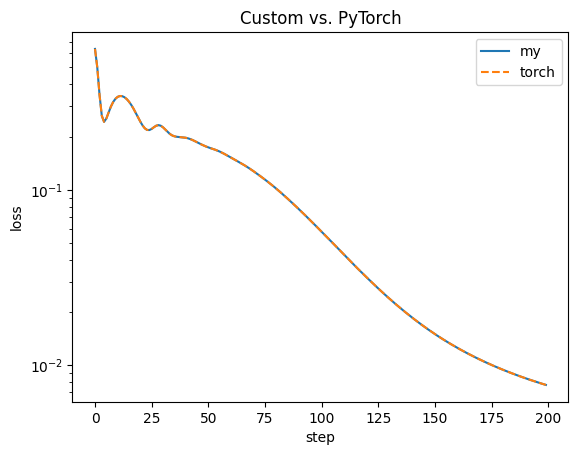

In [90]:
# Comparison to torch builin:
import copy

base = DLModel(len(num_cols), cardinalities, emb_dims)
loss_fn = nn.BCEWithLogitsLoss()

def run(opt_cls, n_steps=200):
    m = copy.deepcopy(base)
    m.eval()
    opt = opt_cls(m.parameters(), lr=1e-2, momentum=0.9, weight_decay=1e-2)
    losses = []
    for _ in range(n_steps):
        opt.zero_grad()
        loss = loss_fn(m(xc, xn), yb)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

l_mine, l_torch = run(SGDC), run(torch.optim.SGD)
print("max abs difference:", max(abs(a - b) for a, b in zip(l_mine, l_torch)))

plt.plot(l_mine, label="my")
plt.plot(l_torch, "--", label="torch")
plt.xlabel("step"); plt.ylabel("loss"); plt.yscale("log")
plt.title("Custom vs. PyTorch"); plt.legend(); plt.show()

This block was added after the parameter tuning, contains feature engineering

In [91]:
from sklearn.preprocessing import QuantileTransformer

train_orig = pd.read_csv("application_train.csv")
test_orig = pd.read_csv("application_test.csv")

def add_features(df):
    out = pd.DataFrame(index=df.index)
    inc = df["AMT_INCOME_TOTAL"]
    emp = df["DAYS_EMPLOYED"].replace(365243, np.nan)
    ext = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
    out["fe_credit_income"]  = df["AMT_CREDIT"] / inc
    out["fe_annuity_income"] = df["AMT_ANNUITY"] / inc
    out["fe_credit_term"]    = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
    out["fe_goods_credit"]   = df["AMT_GOODS_PRICE"] / df["AMT_CREDIT"]
    out["fe_income_person"]  = inc / df["CNT_FAM_MEMBERS"]
    out["fe_children_ratio"] = df["CNT_CHILDREN"] / df["CNT_FAM_MEMBERS"]

    out["fe_ext_mean"] = ext.mean(axis=1)
    out["fe_ext_std"]  = ext.std(axis=1)
    out["fe_ext_min"]  = ext.min(axis=1)
    out["fe_ext_max"]  = ext.max(axis=1)
    out["fe_ext_prod"] = ext.prod(axis=1, min_count=3)
    out["fe_ext_nan"]  = ext.isna().sum(axis=1)

    out["fe_employed_age"] = emp / df["DAYS_BIRTH"]
    out["fe_phone_age"]    = df["DAYS_LAST_PHONE_CHANGE"] / df["DAYS_BIRTH"]
    out["fe_id_age"]       = df["DAYS_ID_PUBLISH"] / df["DAYS_BIRTH"]
    out["fe_reg_age"]      = df["DAYS_REGISTRATION"] / df["DAYS_BIRTH"]

    return out.replace([np.inf, -np.inf], np.nan)

assert len(train_orig) == len(train_x) and len(test_orig) == len(test)
train_orig = train_orig.drop(columns=["TARGET"])

fe_tr = add_features(train_orig)
fe_te = add_features(test_orig)
new_cols = list(fe_tr.columns)

med = fe_tr.median()
fe_tr, fe_te = fe_tr.fillna(med), fe_te.fillna(med)

qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                         subsample=10**9, random_state=67).fit(fe_tr)
fe_tr = pd.DataFrame(qt.transform(fe_tr), columns=new_cols)
fe_te = pd.DataFrame(qt.transform(fe_te), columns=new_cols)

train_x = pd.concat([train_x.reset_index(drop=True), fe_tr], axis=1)
test    = pd.concat([test.reset_index(drop=True), fe_te], axis=1)
num_cols = num_cols + new_cols

assert not train_x[num_cols].isna().any().any(), "NaN in train features"
assert not test[num_cols].isna().any().any(), "NaN in test features"

---

In [92]:
import math
from sklearn.metrics import log_loss, roc_auc_score
from collections import defaultdict

Xc_t = torch.from_numpy(train_x[cat_cols].values.astype(np.int64)).to(device)
Xn_t = torch.from_numpy(train_x[num_cols].values.astype(np.float32)).to(device)
y_t = torch.from_numpy(train_y["TARGET"].values.astype(np.float32)).to(device)
Xc_te_t = torch.from_numpy(test[cat_cols].values.astype(np.int64)).to(device)
Xn_te_t = torch.from_numpy(test[num_cols].values.astype(np.float32)).to(device)

@torch.no_grad()
def predict(model, xc, xn, bs=8192):
    model.eval()
    out = torch.empty(len(xn), device=device)
    for i in range(0, len(xn), bs):
        out[i:i + bs] = torch.sigmoid(model(xc[i:i + bs], xn[i:i + bs]))
    return out.cpu().numpy()

In [93]:
def train_fold(params, tr, va, epochs=15, patience=3, predict_test=True):
    set_seed(67)
    tr_t = torch.as_tensor(tr, device=device)
    va_t = torch.as_tensor(va, device=device)
    xc_va, xn_va = Xc_t[va_t], Xn_t[va_t]

    bs = params["batch_size"]
    steps_per_epoch = math.ceil(len(tr) / bs)

    model = DLModel(len(num_cols), cardinalities, emb_dims, hidden=params["hidden"],
                    n_layers=params["n_layers"], dropout=params["dropout"]).to(device)
    opt = SGDC(model.parameters(), lr=params["lr"], momentum=0.9,
           weight_decay=params["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=params["lr"], epochs=epochs, steps_per_epoch=steps_per_epoch
    )
    loss_fn = nn.BCEWithLogitsLoss()
    gen = torch.Generator(device=device).manual_seed(67)

    hist = {"train_loss": [], "val_loss": [], "val_auc": [], "lr": [], "grad": []}
    best_auc, best_state, bad = -1, None, 0

    for ep in range(epochs):
        model.train()
        total = torch.zeros((), device=device)
        grads = defaultdict(list)
        perm = tr_t[torch.randperm(len(tr_t), device=device, generator=gen)]

        for i, start in enumerate(range(0, len(perm), bs)):
            idx = perm[start:start + bs]
            yb = y_t[idx]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xc_t[idx], Xn_t[idx]), yb)
            loss.backward()
            if i % 50 == 0:
                for name, p in model.named_parameters():
                    if p.grad is not None:
                        grads[name].append(p.grad.norm().item())
            opt.step()
            sched.step()
            total += loss.detach() * len(idx)

        hist["lr"].append(opt.param_groups[0]["lr"])

        p_va = predict(model, xc_va, xn_va)
        auc = roc_auc_score(y[va], p_va)
        hist["train_loss"].append(total.item() / len(tr))
        hist["val_loss"].append(log_loss(y[va], p_va))
        hist["val_auc"].append(auc)
        hist["grad"].append({k: np.mean(v) for k, v in grads.items()})

        if auc > best_auc:
            best_auc, bad = auc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    p_va = predict(model, xc_va, xn_va)
    p_te = predict(model, Xc_te_t, Xn_te_t) if predict_test else None
    return p_va, p_te, hist


def run_cv(params, n_folds=5, predict_test=True):
    oof, test_pred = np.zeros(len(y)), np.zeros(len(Xn_te_t))
    fold_auc, hists = [], []
    for k in range(n_folds):
        tr, va = np.where(folds != k)[0], np.where(folds == k)[0]
        p_va, p_te, h = train_fold(params, tr, va, predict_test=predict_test)
        oof[va] = p_va
        if predict_test:
            test_pred += p_te / n_folds
        fold_auc.append(roc_auc_score(y[va], p_va))
        hists.append(h)
        print(f"fold {k}: AUC {fold_auc[-1]:.4f}")
    return oof, test_pred, fold_auc, hists

In [94]:
rng = random.Random(67)
params = {
    "lr": [0.05, 0.08, 0.1], "hidden": [512, 1024], "n_layers": [3, 4],
    "dropout": [0.05, 0.1, 0.2], "weight_decay": [1e-4], "batch_size": [2048],
}
log = []
for t in range(8):
    p = {k: rng.choice(v) for k, v in params.items()}
    t0 = time.time()
    _, _, fa, _ = run_cv(p, n_folds=2, predict_test=False)
    log.append({**p, "cv_auc": np.mean(fa), "cv_std": np.std(fa), "sec": time.time() - t0})
    print(f"trial {t}: AUC {log[-1]['cv_auc']:.5f} ± {log[-1]['cv_std']:.5f}, {log[-1]['sec']:.0f}s")
    pd.DataFrame(log).to_csv("nn_tuning_log.csv", index=False)

display(pd.DataFrame(log).sort_values("cv_auc", ascending=False))

fold 0: AUC 0.7484
fold 1: AUC 0.7463
trial 0: AUC 0.74735 ± 0.00108, 27s
fold 0: AUC 0.7504
fold 1: AUC 0.7492
trial 1: AUC 0.74978 ± 0.00062, 63s
fold 0: AUC 0.7509
fold 1: AUC 0.7500
trial 2: AUC 0.75042 ± 0.00044, 23s
fold 0: AUC 0.7482
fold 1: AUC 0.7478
trial 3: AUC 0.74795 ± 0.00020, 23s
fold 0: AUC 0.7479
fold 1: AUC 0.7463
trial 4: AUC 0.74710 ± 0.00080, 27s
fold 0: AUC 0.7509
fold 1: AUC 0.7500
trial 5: AUC 0.75042 ± 0.00044, 23s
fold 0: AUC 0.7505
fold 1: AUC 0.7491
trial 6: AUC 0.74981 ± 0.00067, 27s
fold 0: AUC 0.7500
fold 1: AUC 0.7478
trial 7: AUC 0.74890 ± 0.00107, 27s


,lr,hidden,n_layers,dropout,weight_decay,batch_size,cv_auc,cv_std,sec
2,0.10,512,3,0.10,0.0001,2048,0.750420,0.000443,23.205744
5,0.10,512,3,0.10,0.0001,2048,0.750420,0.000443,22.791816
6,0.10,512,4,0.05,0.0001,2048,0.749808,0.000673,27.215934
1,0.10,1024,4,0.20,0.0001,2048,0.749775,0.000616,62.709435
7,0.08,512,4,0.10,0.0001,2048,0.748898,0.001065,27.201044
3,0.08,512,3,0.20,0.0001,2048,0.747954,0.000198,22.581305
0,0.05,512,4,0.10,0.0001,2048,0.747352,0.001082,26.694100
4,0.08,512,4,0.20,0.0001,2048,0.747103,0.000800,27.169065


---

In [95]:
from sklearn.metrics import average_precision_score

y = train_y["TARGET"].values

best = max(log, key=lambda r: r["cv_auc"])
best_params = {k: best[k] for k in params}
print("Best params:", best_params)

oof_nn, test_nn, fold_auc, hists = run_cv(best_params)

def recall_at_k(y_true, p, k=0.10):  # the alternative metric from Part 1
    thr = np.quantile(p, 1 - k)
    return (p[y_true == 1] >= thr).mean()

# metrics
print("Per-fold AUC:", np.round(fold_auc, 5))
print(f"CV AUC:        {np.mean(fold_auc):.5f} ± {np.std(fold_auc):.5f}")
print(f"OOF AUC:       {roc_auc_score(y, oof_nn):.5f}")
print(f"PR-AUC:        {average_precision_score(y, oof_nn):.5f}")
print(f"LogLoss:       {log_loss(y, oof_nn):.5f}")
print(f"Recall@10%:    {recall_at_k(y, oof_nn):.5f}")

np.save("oof_nn.npy", oof_nn)
np.save("test_nn.npy", test_nn)
pd.DataFrame({"SK_ID_CURR": test_ids.values, "TARGET": test_nn}).to_csv("sub_nn.csv", index=False)

Best params: {'lr': 0.1, 'hidden': 512, 'n_layers': 3, 'dropout': 0.1, 'weight_decay': 0.0001, 'batch_size': 2048}
fold 0: AUC 0.7509
fold 1: AUC 0.7500
fold 2: AUC 0.7455
fold 3: AUC 0.7519
fold 4: AUC 0.7526
Per-fold AUC: [0.75086 0.74998 0.74552 0.75193 0.75257]
CV AUC:        0.75017 ± 0.00249
OOF AUC:       0.74971
PR-AUC:        0.23118
LogLoss:       0.24911
Recall@10%:    0.32383


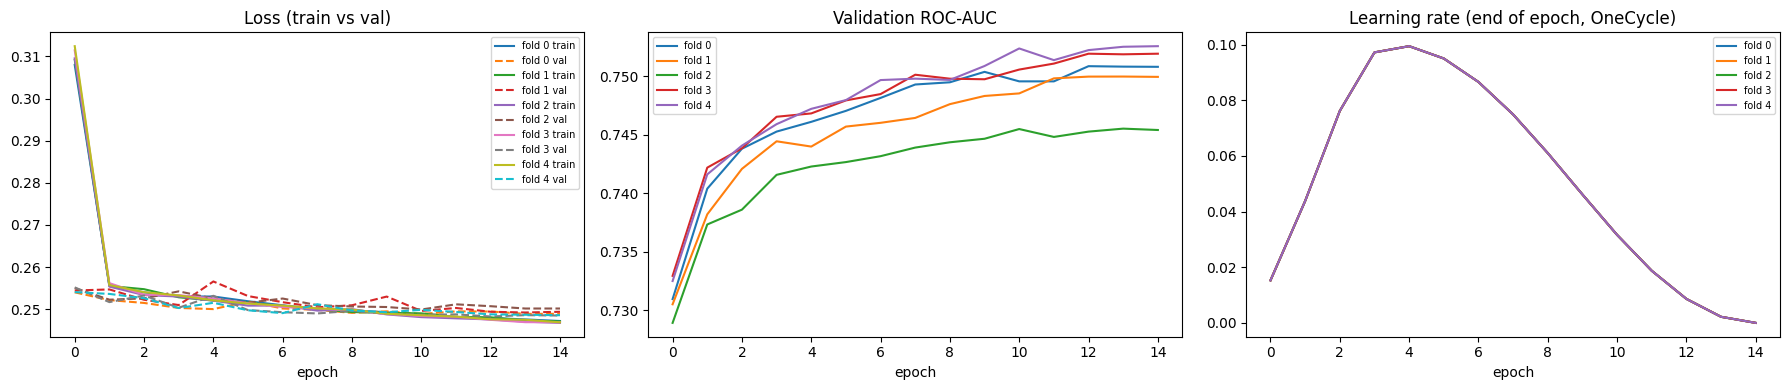

In [96]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for k, h in enumerate(hists):
    ax[0].plot(h["train_loss"], label=f"fold {k} train")
    ax[0].plot(h["val_loss"], "--", label=f"fold {k} val")
    ax[1].plot(h["val_auc"], label=f"fold {k}")
    ax[2].plot(h["lr"], label=f"fold {k}")
ax[0].set_title("Loss (train vs val)")
ax[1].set_title("Validation ROC-AUC")
ax[2].set_title("Learning rate (end of epoch, OneCycle)")
for a in ax:
    a.set_xlabel("epoch")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

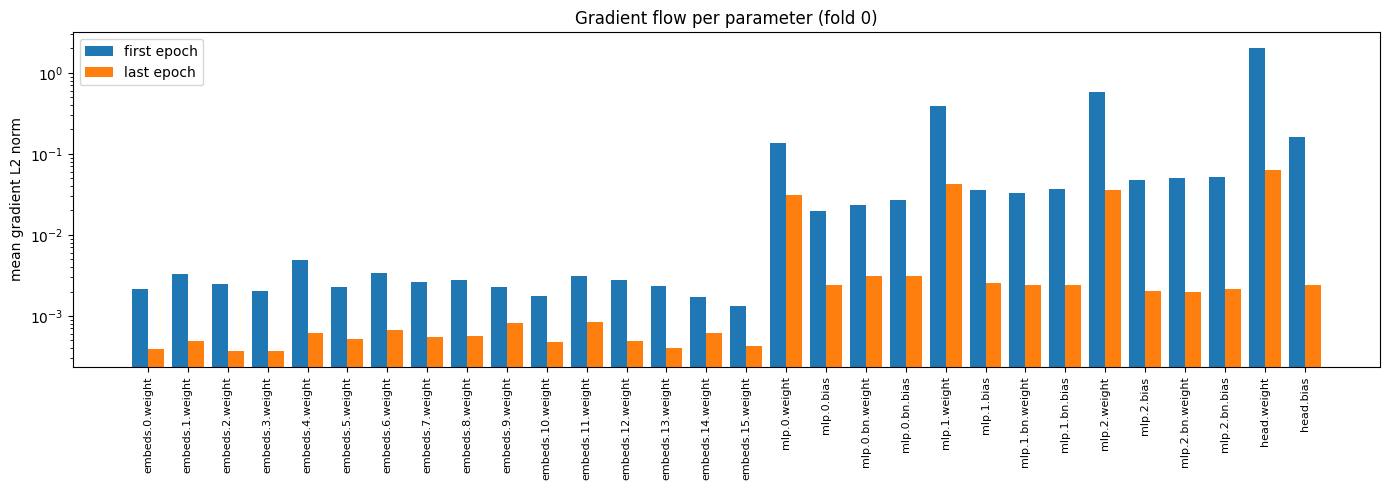

In [97]:
g_first, g_last = hists[0]["grad"][0], hists[0]["grad"][-1]
names = list(g_first.keys())
x = np.arange(len(names))

plt.figure(figsize=(14, 5))
plt.bar(x - 0.2, [g_first[n] for n in names], 0.4, label="first epoch")
plt.bar(x + 0.2, [g_last[n] for n in names], 0.4, label="last epoch")
plt.xticks(x, names, rotation=90, fontsize=8)
plt.yscale("log")
plt.ylabel("mean gradient L2 norm")
plt.title("Gradient flow per parameter (fold 0)")
plt.legend()
plt.tight_layout()
plt.show()

### Results

Local: 0.75017

Public leaderboard: 0.73972

Private leaderboard: 0.73571

Comparison with LightGBM (Part 2): CV 0.758 / Public 0.747 / Private 0.745.

Conclusion: The neural network

`{'lr': 0.1, 'hidden': 512, 'n_layers': 3, 'dropout': 0.1, 'weight_decay': 0.0001, 'batch_size': 2048}`

with custom SGD optimizer has shown that it's local validation is trustworthy, having similar gap between local/subm to LightGBM's. The biggest gap is in fold 2 - ~0.005 lower than all other folds. Recall metric shows good results as well as in LightGBM - ~32% against ~33%. The NN validation/evaluation once more proves that stratified K-Fold was the right strategy.

The model is adequate but weaker than gradient boosting, which is typical for a tabular dataset. Ratio features engineered for this task gave great improvements and allowed the model to cross 0.75 on local validation.

While this model didn't outperform LightGBM, its value will be more important during ensembling part.